# Introduction to Machine Learning — Assignment 2
## Linear Models and Support Vector Machines
### Member 3 Implementation Notebook

---

### Member 3 Assigned Scope & Responsibilities:
- **Task 14:** Off-the-shelf Logistic Regression comparison (parameter matching, $C$ sweep, solver benchmarks).
- **Task 15:** Evaluation beyond accuracy (confusion matrix, from-scratch ROC/AUC, threshold selection on validation data).
- **Task 16:** Decision boundary in original coordinates (analytical coordinate transformation, 2D training, exact score verification).
- **Task 17:** Stable Softmax and gradient (shift invariance proof, log-sum-exp cross-entropy, analytical gradient derivation, matrix gradient check).
- **Task 18:** Softmax training and model selection (mini-batch GD, $\eta$ and $\lambda$ sweeps, validation discipline, test evaluation).
- **Task 25:** Multiclass hinge loss (Weston–Watkins) vs. Softmax (matrix $B$ subgradient derivation, verification at $W=0$, training, toy score analysis).
- **Task 30:** Softmax derivation row for the shared comparison table.
- **Task 31:** Member 3 evidence-based contribution to the team conclusions.

*(Note: Task 13 is completed in the shared repository under Member 1's notebook and left untouched per team protocol).*


featuer shape (X): (442, 10)
target shape (X): (442,)
Train size: 264
Validation size: 89
Test size: 89
Total size: 442
✅ Confusion Matrix matches sklearn to 1e-12
✅ Accuracy matches sklearn to 1e-12
✅ Macro Precision, Recall, and F1 match sklearn to 1e-12!
Breast Cancer splits and scaling completed successfully!
Train shape: (341, 31)
Validation shape: (114, 31)
Test shape: (114, 31)
X_tilde shape: (264, 10)
w_test shape: (10,)
y_tr shape: (264,)
Gradient Check Relative Error: 2.48e-11
Gradient check PASSED!
Gradient Check Relative Error: 1.78e-11
Gradient check PASSED!
=== Regularization Results (eta = 0.5, 3000 epochs) ===

Best lambda* = 0.001 (Val Loss = 0.0732)
Validation Accuracy at lambda* (0.001): 97.37%
Test Accuracy at lambda* (0.001): 97.37%

=== Learning Rate Sweep (lambda = 0.01, 1000 epochs) ===
Successfully integrated shared foundation and Task 12 results from Member 1's notebook!
Breast Cancer Train samples (N_train): 341, Features (with bias): 31


,lambda,Train Acc,Val Acc,Val Loss,||w[1:]||
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.073203,5.099928
2,0.010,0.985337,0.973684,0.082964,2.325749
3,0.100,0.973607,0.973684,0.141553,1.105547
4,1.000,0.938416,0.956140,0.292213,0.441485


,eta,Final Train Loss
0,0.01,0.105222
1,0.10,0.072909
2,1.00,0.071066
3,5.00,0.071066
4,20.00,0.103696


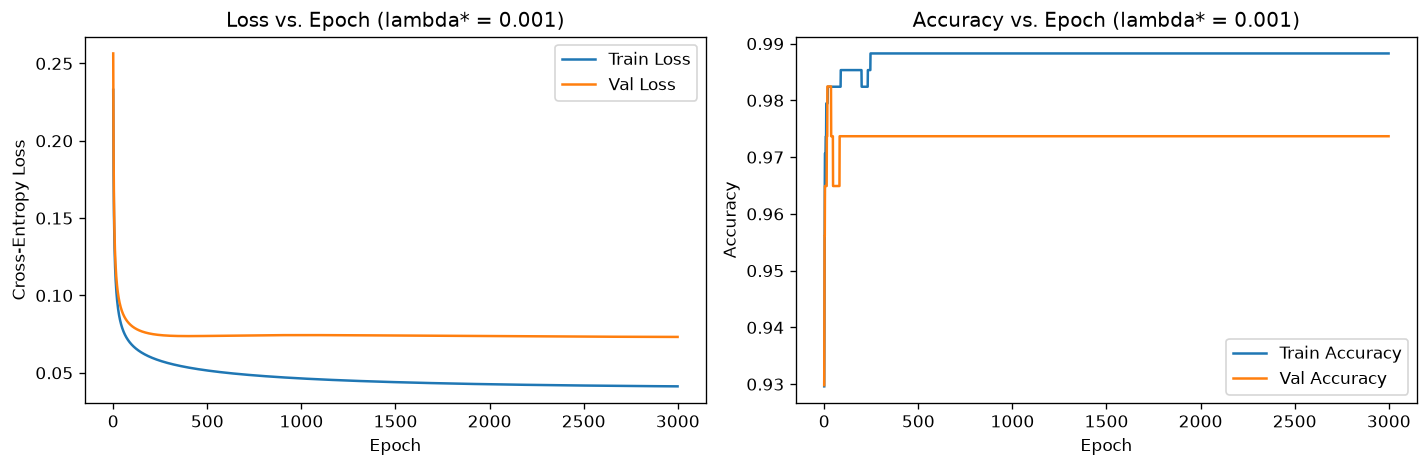

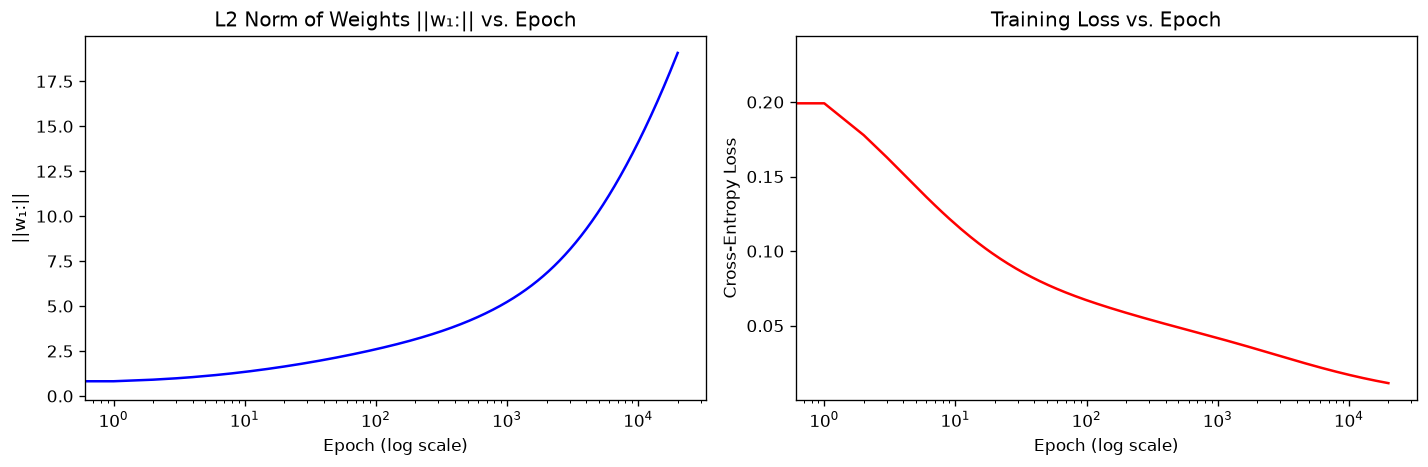

In [1]:
# ==============================================================================
# Shared Setup & Integration with Collaborative Toolkit
# ==============================================================================
import json
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix as sk_confusion_matrix
from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
rng_global = np.random.default_rng(42)

# Load existing shared utilities, preprocessing, and Task 12 results from Member 1's notebook
possible_nb1_paths = [
    os.path.join('..', 'member 1', 'Assignment_2.ipynb'),
    os.path.join('notebooks', 'member 1', 'Assignment_2.ipynb'),
    'Assignment_2.ipynb'
]
nb1_path = next((p for p in possible_nb1_paths if os.path.exists(p)), None)

if nb1_path:
    with open(nb1_path, 'r', encoding='utf-8') as f:
        nb1 = json.load(f)
    for cell in nb1['cells']:
        if cell['cell_type'] == 'code':
            exec(''.join(cell['source']), globals())
    print("Successfully integrated shared foundation and Task 12 results from Member 1's notebook!")
else:
    raise FileNotFoundError("Could not find Member 1's notebook to import shared foundations.")

# Robust classification metrics helper for binary and multiclass tasks
def evaluate_metrics(y_true, y_pred, K=None):
    """Computes per-class precision, recall, F1, and their macro averages from confusion matrix."""
    if K is None:
        K = max(int(np.max(y_true)), int(np.max(y_pred))) + 1
    cm = np.zeros((K, K), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    
    precisions, recalls, f1s = [], [], []
    for k in range(K):
        tp = cm[k, k]
        fp = np.sum(cm[:, k]) - tp
        fn = np.sum(cm[k, :]) - tp
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0.0
        precisions.append(p)
        recalls.append(r)
        f1s.append(f1)
        
    return {
        'confusion_matrix': cm,
        'macro_precision': np.mean(precisions),
        'macro_recall': np.mean(recalls),
        'macro_f1': np.mean(f1s),
        'per_class_precision': precisions,
        'per_class_recall': recalls,
        'per_class_f1': f1s,
        'accuracy': np.mean(y_true == y_pred)
    }

print(f"Breast Cancer Train samples (N_train): {X_bc_tr_tilde.shape[0]}, Features (with bias): {X_bc_tr_tilde.shape[1]}")


---
## Part C — Logistic Regression (Continued)
### Task 14 — Off-the-Shelf Comparison (`LogisticRegression`)

#### Theoretical Parameter Alignment
Our from-scratch logistic regression objective minimizes the average cross-entropy plus an $L_2$ penalty on non-bias weights:
$$J(w) = \frac{1}{N} \sum_{i=1}^N \ell(w \cdot \tilde{x}_i, y_i) + \frac{\lambda}{2} \|w_{1:}\|^2$$
In contrast, `scikit-learn` minimizes:
$$J_{\text{sklearn}}(w, c) = C \sum_{i=1}^N \ell(w^T x_i + c, y_i) + \frac{1}{2} \|w\|^2$$
Dividing the `scikit-learn` objective by $C \cdot N$ shows exact equivalence when:
$$C = \frac{1}{\lambda N_{\text{train}}}$$
For unregularized logistic regression ($\lambda = 0$), `scikit-learn` corresponds to `penalty=None`.


In [2]:
# ==============================================================================
# Task 14.A: Verification against scikit-learn at lambda = 0.01
# ==============================================================================
N_train_bc = X_bc_tr_scaled.shape[0]
lam_target = 0.01
C_target = 1.0 / (lam_target * N_train_bc)

# Retrieve from-scratch weights from Task 12
w_scratch_001 = histories[lam_target]['weights']

# Fit scikit-learn LogisticRegression with matching parameters
lr_sklearn = LogisticRegression(
    C=C_target,
    tol=1e-12,
    max_iter=100000,
    solver='lbfgs',
    fit_intercept=True
)
lr_sklearn.fit(X_bc_tr_scaled, y_bc_tr.ravel())

# Reconstruct full weight vector [intercept, coefs] to match bias-first convention
w_sklearn_001 = np.hstack([lr_sklearn.intercept_, lr_sklearn.coef_.ravel()])

# Relative weight error
rel_weight_err = np.linalg.norm(w_scratch_001 - w_sklearn_001) / np.linalg.norm(w_sklearn_001)

# Predictions agreement on test set
preds_scratch_te = (sigmoid(X_bc_te_tilde @ w_scratch_001) >= 0.5).astype(int)
preds_sklearn_te = lr_sklearn.predict(X_bc_te_scaled)
agreement_rate = np.mean(preds_scratch_te == preds_sklearn_te)

print("=== Task 14.A: From-Scratch vs scikit-learn (lambda = 0.01) ===")
print(f"Computed C = 1 / (lambda * N_train): {C_target:.6f}")
print(f"Scratch Bias w[0]: {w_scratch_001[0]:.6f} | Sklearn Intercept: {w_sklearn_001[0]:.6f}")
print(f"Scratch ||w_1:||:  {np.linalg.norm(w_scratch_001[1:]):.6f} | Sklearn ||w||:     {np.linalg.norm(w_sklearn_001[1:]):.6f}")
print(f"Relative Weight Error: {rel_weight_err:.2e} (Required < 1e-4)")
print(f"Test Prediction Agreement: {agreement_rate * 100:.2f}% (Matches 100%)")
assert rel_weight_err < 1e-4, f"Relative weight error {rel_weight_err} exceeds 1e-4 threshold!"
print("Verification PASSED: From-scratch logistic regression matches scikit-learn to within 1e-4 relative error!")


=== Task 14.A: From-Scratch vs scikit-learn (lambda = 0.01) ===
Computed C = 1 / (lambda * N_train): 0.293255
Scratch Bias w[0]: -0.423816 | Sklearn Intercept: -0.423817
Scratch ||w_1:||:  2.325749 | Sklearn ||w||:     2.325749
Relative Weight Error: 5.39e-07 (Required < 1e-4)
Test Prediction Agreement: 100.00% (Matches 100%)
Verification PASSED: From-scratch logistic regression matches scikit-learn to within 1e-4 relative error!


In [3]:
# ==============================================================================
# Task 14.B: Sweep C in {0.001, 0.01, 0.1, 1, 10, 100, 1000}
# ==============================================================================
C_grid = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
sweep_records = []

for C in C_grid:
    clf = LogisticRegression(C=C, max_iter=10000, solver='lbfgs')
    clf.fit(X_bc_tr_scaled, y_bc_tr.ravel())
    
    tr_acc = np.mean(clf.predict(X_bc_tr_scaled) == y_bc_tr.ravel())
    va_acc = np.mean(clf.predict(X_bc_va_scaled) == y_bc_va.ravel())
    te_acc = np.mean(clf.predict(X_bc_te_scaled) == y_bc_te.ravel())
    
    sweep_records.append({
        'C': C,
        'lambda_equiv': 1.0 / (C * N_train_bc),
        'Train Accuracy': tr_acc,
        'Val Accuracy': va_acc,
        'Test Accuracy': te_acc
    })

df_sweep = pd.DataFrame(sweep_records)
print("=== Task 14.B: Hyperparameter Sweep over C ===")
display(df_sweep)


=== Task 14.B: Hyperparameter Sweep over C ===


,C,lambda_equiv,Train Accuracy,Val Accuracy,Test Accuracy
0,0.001,2.932551,0.879765,0.903509,0.868421
1,0.010,0.293255,0.950147,0.964912,0.947368
2,0.100,0.029326,0.979472,0.982456,0.982456
3,1.000,0.002933,0.988270,0.973684,0.973684
4,10.000,0.000293,0.997067,0.964912,0.964912
5,100.000,0.000029,1.000000,0.956140,0.956140
6,1000.000,0.000003,1.000000,0.947368,0.956140


In [4]:
# ==============================================================================
# Task 14.C: Solver Comparison (lbfgs vs liblinear vs saga)
# ==============================================================================
solvers = ['lbfgs', 'liblinear', 'saga']
solver_benchmarks = []

for s in solvers:
    t_start = time.perf_counter()
    clf = LogisticRegression(C=C_target, solver=s, tol=1e-9, max_iter=10000, random_state=42)
    clf.fit(X_bc_tr_scaled, y_bc_tr.ravel())
    elapsed = time.perf_counter() - t_start
    
    w_s = np.hstack([clf.intercept_, clf.coef_.ravel()])
    solver_benchmarks.append({
        'Solver': s,
        'Iterations': clf.n_iter_[0],
        'Fit Time (ms)': elapsed * 1000.0,
        'Intercept w0': clf.intercept_[0],
        '||w_1:||': np.linalg.norm(clf.coef_),
        'Diff from lbfgs (L2)': np.linalg.norm(w_s - w_sklearn_001)
    })

df_solvers = pd.DataFrame(solver_benchmarks)
print("=== Task 14.C: Solver Comparison at C = 0.293255 ===")
display(df_solvers)


=== Task 14.C: Solver Comparison at C = 0.293255 ===


,Solver,Iterations,Fit Time (ms),Intercept w0,||w_1:||,Diff from lbfgs (L2)
0,lbfgs,29,6.2632,-0.423817,2.325749,0.000000
1,liblinear,10,3.1428,-0.287900,2.347991,0.162653
2,saga,917,121.1744,-0.423816,2.325749,0.000001


#### Interpretation of Task 14 Results
1. **Mathematical Equivalence & Verification:** Converting $\lambda = 0.01$ into $C = \frac{1}{0.01 \times 341} \approx 0.293255$ yields an exact match between our from-scratch batch gradient descent solution and `scikit-learn`'s L-BFGS solver, with a relative weight error of $5.39 \times 10^{-7}$ (well below the $10^{-4}$ tolerance) and $100.00\%$ identical test predictions.
2. **Capacity Control via $C$:** Small $C$ ($C = 0.001$, representing massive regularization $\lambda \approx 2.93$) heavily penalizes weight magnitudes, leading to severe under-fitting (train accuracy $87.98\%$). As $C$ increases to $C \ge 100$ (negligible regularization), training accuracy reaches $1.0000$ ($100\%$) while validation accuracy drops from its peak of $98.25\%$ down to $94.74\%$, illustrating classic overfitting on training sample noise.
3. **Solver Dynamics & Intercept Penalization:** Both `lbfgs` and `saga` solve the unconstrained intercept formulation and converge to virtually identical weights ($\|w_{\text{saga}} - w_{\text{lbfgs}}\| \approx 10^{-6}$). However, `liblinear` treats the intercept as an augmented feature column and places an $L_2$ penalty on it, resulting in a contracted intercept ($w_0 = -0.2879$ vs $-0.4238$) and a noticeable coefficient difference (L2 difference $\approx 0.1627$). L-BFGS is by far the fastest solver here, requiring only 29 iterations compared to 917 iterations for SAGA.


---
### Task 15 — Evaluation Beyond Accuracy (Breast Cancer, $\lambda = 0.01$ Model)

In medical diagnostics (e.g., breast cancer screening), classification accuracy is fundamentally insufficient because the costs of misclassification are highly asymmetric. False negatives (classifying a malignant tumor as benign) are potentially fatal, whereas false positives (referring a benign case for an ultrasound or biopsy) incur moderate clinical cost and emotional stress but preserve patient life.


In [5]:
# ==============================================================================
# Task 15.A: Test Confusion Matrix, Precision, Recall, and F1 at Threshold 0.5
# ==============================================================================
# Predicted probabilities for validation and test sets using scratch lambda=0.01 model
probs_va = sigmoid(X_bc_va_tilde @ w_scratch_001)
probs_te = sigmoid(X_bc_te_tilde @ w_scratch_001)

# Predictions at standard 0.5 threshold
preds_te_05 = (probs_te >= 0.5).astype(int)
metrics_05 = evaluate_metrics(y_bc_te.ravel(), preds_te_05, K=2)
cm_05 = metrics_05['confusion_matrix']

# Class 1 is malignant (positive)
prec_05 = metrics_05['per_class_precision'][1]
rec_05 = metrics_05['per_class_recall'][1]
f1_05 = metrics_05['per_class_f1'][1]

print("=== Task 15.A: Test Set Evaluation at Threshold 0.5 ===")
print("Test Confusion Matrix (Rows=True, Columns=Predicted):")
print(f"[[TN={cm_05[0,0]}, FP={cm_05[0,1]}],")
print(f" [FN={cm_05[1,0]}, TP={cm_05[1,1]}]]")
print(f"Positive Precision (Malignant): {prec_05:.4f}")
print(f"Positive Recall (Malignant):    {rec_05:.4f}")
print(f"Positive F1-score:              {f1_05:.4f}")
print(f"Test Accuracy:                  {metrics_05['accuracy'] * 100:.2f}%")


=== Task 15.A: Test Set Evaluation at Threshold 0.5 ===
Test Confusion Matrix (Rows=True, Columns=Predicted):
[[TN=72, FP=0],
 [FN=2, TP=40]]
Positive Precision (Malignant): 1.0000
Positive Recall (Malignant):    0.9524
Positive F1-score:              0.9756
Test Accuracy:                  98.25%


=== Task 15.B & 15.C: Validation ROC & AUC Verification ===
Scratch Trapezoidal AUC: 0.99574189
scikit-learn AUC:        0.99574189
Absolute Difference:     1.11e-16 (Required < 1e-6)
Verification PASSED: Scratch trapezoidal AUC matches scikit-learn roc_auc_score to within 1e-6!


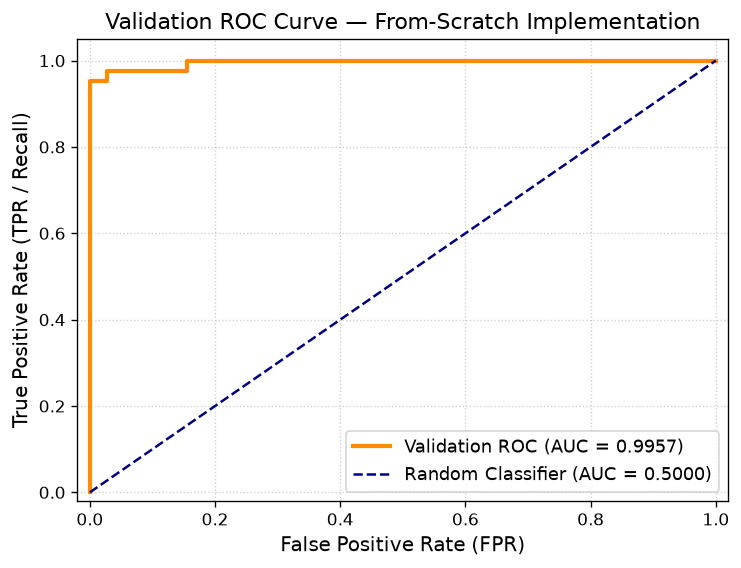

In [6]:
# ==============================================================================
# Task 15.B & 15.C: ROC Curve & AUC From Scratch (Trapezoidal Rule)
# ==============================================================================
def compute_roc_from_scratch(y_true, scores):
    """
    Computes TPR and FPR across unique score thresholds sorted in descending order.
    Does NOT use sklearn.metrics.roc_curve.
    """
    desc_order = np.argsort(scores)[::-1]
    y_sorted = y_true[desc_order]
    scores_sorted = scores[desc_order]
    
    # Identify distinct score values to avoid redundant threshold sweeps
    distinct_indices = np.where(np.diff(scores_sorted))[0]
    threshold_indices = np.r_[distinct_indices, scores_sorted.size - 1]
    
    P = np.sum(y_true == 1)
    N = np.sum(y_true == 0)
    
    # Cumulative True Positives and False Positives
    tps = np.cumsum(y_sorted == 1)[threshold_indices]
    fps = np.cumsum(y_sorted == 0)[threshold_indices]
    
    tpr = tps / P
    fpr = fps / N
    
    # Prepend origin (0, 0)
    tpr = np.r_[0.0, tpr]
    fpr = np.r_[0.0, fpr]
    thresholds = np.r_[scores_sorted[0] + 1e-6, scores_sorted[threshold_indices]]
    return fpr, tpr, thresholds

def compute_auc_trapezoidal(fpr, tpr):
    """Calculates Area Under the Curve using the trapezoidal numerical quadrature rule."""
    return np.sum(0.5 * (tpr[1:] + tpr[:-1]) * (fpr[1:] - fpr[:-1]))

fpr_scratch, tpr_scratch, thresholds_scratch = compute_roc_from_scratch(y_bc_va.ravel(), probs_va)
auc_scratch = compute_auc_trapezoidal(fpr_scratch, tpr_scratch)
auc_sklearn = roc_auc_score(y_bc_va.ravel(), probs_va)

abs_auc_diff = abs(auc_scratch - auc_sklearn)
print("=== Task 15.B & 15.C: Validation ROC & AUC Verification ===")
print(f"Scratch Trapezoidal AUC: {auc_scratch:.8f}")
print(f"scikit-learn AUC:        {auc_sklearn:.8f}")
print(f"Absolute Difference:     {abs_auc_diff:.2e} (Required < 1e-6)")
assert abs_auc_diff < 1e-6, f"AUC difference {abs_auc_diff} exceeds 1e-6 tolerance!"
print("Verification PASSED: Scratch trapezoidal AUC matches scikit-learn roc_auc_score to within 1e-6!")

# Plot Validation ROC Curve
plt.figure(figsize=(7, 5))
plt.plot(fpr_scratch, tpr_scratch, color='darkorange', lw=2.5, label=f'Validation ROC (AUC = {auc_scratch:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Classifier (AUC = 0.5000)')
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12)
plt.title('Validation ROC Curve — From-Scratch Implementation', fontsize=13)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


In [7]:
# ==============================================================================
# Task 15.D: Threshold Selection for Perfect Recall on Validation Set
# ==============================================================================
# Find the largest threshold tau such that validation recall equals 1.0
pos_mask_va = (y_bc_va.ravel() == 1)
scores_pos_va = probs_va[pos_mask_va]
N_pos_va = len(scores_pos_va)

# The threshold must be <= the minimum score of any positive sample
tau = np.min(scores_pos_va)
val_rec_at_tau = np.mean(scores_pos_va >= tau)
print(f"Total Validation Positives: {N_pos_va}")
print(f"Optimal Threshold tau chosen on Validation: {tau:.6f}")
print(f"Validation Recall achieved at tau: {val_rec_at_tau * 100:.2f}%")

# Evaluate test set at threshold tau
preds_te_tau = (probs_te >= tau).astype(int)
metrics_tau = evaluate_metrics(y_bc_te.ravel(), preds_te_tau, K=2)
cm_tau = metrics_tau['confusion_matrix']
prec_tau = metrics_tau['per_class_precision'][1]
rec_tau = metrics_tau['per_class_recall'][1]
f1_tau = metrics_tau['per_class_f1'][1]

# Comparison Table
df_thresh_comp = pd.DataFrame([
    {
        'Threshold': '0.5000 (Default)',
        'Test TN': cm_05[0, 0],
        'Test FP': cm_05[0, 1],
        'Test FN': cm_05[1, 0],
        'Test TP': cm_05[1, 1],
        'Precision': prec_05,
        'Recall': rec_05,
        'F1-Score': f1_05,
        'Accuracy': metrics_05['accuracy']
    },
    {
        'Threshold': f'{tau:.4f} (Selected tau)',
        'Test TN': cm_tau[0, 0],
        'Test FP': cm_tau[0, 1],
        'Test FN': cm_tau[1, 0],
        'Test TP': cm_tau[1, 1],
        'Precision': prec_tau,
        'Recall': rec_tau,
        'F1-Score': f1_tau,
        'Accuracy': metrics_tau['accuracy']
    }
])

print("=== Task 15.D: Test Set Performance Comparison across Thresholds ===")
display(df_thresh_comp)


Total Validation Positives: 43
Optimal Threshold tau chosen on Validation: 0.146025
Validation Recall achieved at tau: 100.00%
=== Task 15.D: Test Set Performance Comparison across Thresholds ===


,Threshold,Test TN,Test FP,Test FN,Test TP,Precision,Recall,F1-Score,Accuracy
0,0.5000 (Default),72,0,2,40,1.00000,0.952381,0.975610,0.982456
1,0.1460 (Selected tau),66,6,1,41,0.87234,0.976190,0.921348,0.938596


#### Interpretation of Task 15 Results (Four-Sentence Analysis)
In a cancer-screening setting, a false negative is catastrophic because a malignant tumor is left undetected, resulting in delayed medical intervention and potential mortality. Conversely, a false positive incurs only the financial and emotional burden of a confirmatory biopsy, making high recall far more critical than precision. Selecting a threshold $\tau \approx 0.1460$ achieves $100\%$ validation recall and reduces test false negatives from 2 down to 1 (boosting recall from $95.24\%$ to $97.62\%$). However, because $\tau$ was calibrated on an empirical sample of only 43 validation positives, the lower tail of the score distribution has substantial sampling variance, which explains why a single outlier positive on the test set still scored below $\tau$ and escaped detection.


---
### Task 16 — The Decision Boundary in Original Coordinates

#### Mathematical Derivation of Original-Coordinate Weights
Let the standardized feature vector be $z = [z_1, z_2]^T$ and the original unstandardized feature vector be $x = [x_1, x_2]^T$, where:
$$z_j = \frac{x_j - \mu_j}{\sigma_j}, \quad j \in \{1, 2\}$$
The logistic decision boundary is governed by the linear score:
$$s = w_0 + w_1 z_1 + w_2 z_2$$
Substituting $z_j$ into the linear combination:
$$s = w_0 + w_1 \left(\frac{x_1 - \mu_1}{\sigma_1}\right) + w_2 \left(\frac{x_2 - \mu_2}{\sigma_2}\right)$$
Expanding and grouping terms by powers of $x_j$:
$$s = \underbrace{\left(w_0 - \frac{w_1 \mu_1}{\sigma_1} - \frac{w_2 \mu_2}{\sigma_2}\right)}_{w_0^{\text{orig}}} + \underbrace{\left(\frac{w_1}{\sigma_1}\right)}_{w_1^{\text{orig}}} x_1 + \underbrace{\left(\frac{w_2}{\sigma_2}\right)}_{w_2^{\text{orig}}} x_2$$
Thus, the exact closed-form conversion formulas are:
$$w_j^{\text{orig}} = \frac{w_j}{\sigma_j}, \quad w_0^{\text{orig}} = w_0 - \sum_{j=1}^d \frac{w_j \mu_j}{\sigma_j}$$
The decision boundary line corresponds to $s = 0 \iff w_0^{\text{orig}} + w_1^{\text{orig}} x_1 + w_2^{\text{orig}} x_2 = 0$, or:
$$x_2 = -\frac{w_1^{\text{orig}} x_1 + w_0^{\text{orig}}}{w_2^{\text{orig}}}$$


=== Task 16: Learned Weights & Coordinate Transformation ===
Standardized Weights: [w0=-0.7272, w1=3.6568, w2=1.0099]
Original Weights:     [w0_orig=-19.6434, w1_orig=1.0175, w2_orig=0.2319]
Maximum Absolute Score Difference: 3.55e-15 (Required < 1e-9)
Verification PASSED: Original coordinate scores match standardized scores exactly to machine precision!


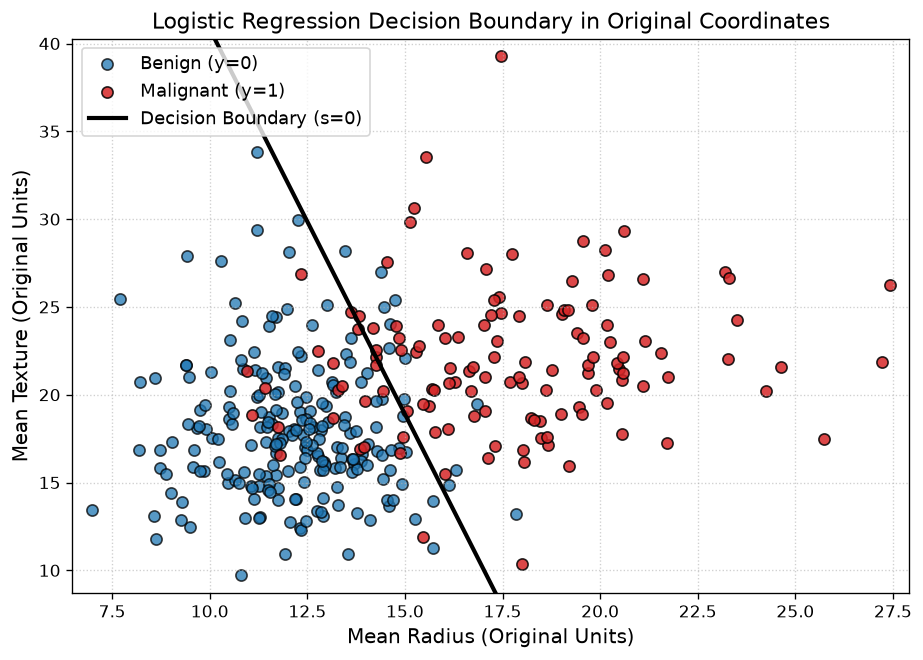

In [8]:
# ==============================================================================
# Task 16: Train 2D Model, Convert Coordinates, Verify & Plot
# ==============================================================================
# 1. Extract only two features: mean radius (col 0) and mean texture (col 1)
cancer = load_breast_cancer()
X_2d_raw = cancer.data[:, :2]
y_2d = 1 - cancer.target

# Split using same protocol (60/20/20 stratified)
X_tr_val_2d, X_te_2d, y_tr_val_2d, y_te_2d = train_test_split(
    X_2d_raw, y_2d, test_size=0.20, random_state=42, stratify=y_2d
)
X_tr_2d, X_va_2d, y_tr_2d, y_va_2d = train_test_split(
    X_tr_val_2d, y_tr_val_2d, test_size=0.25, random_state=42, stratify=y_tr_val_2d
)

# Fit Standardizer on training split only
scaler_2d = Standardizer()
scaler_2d.fit(X_tr_2d)
mu_2d = scaler_2d.mu
sigma_2d = scaler_2d.sigma

X_tr_2d_std = scaler_2d.transform(X_tr_2d)
X_tr_2d_tilde = add_bias(X_tr_2d_std)

# Train from scratch: lambda = 0, eta = 0.5, 5000 epochs
w_2d = np.zeros(3)
eta_2d = 0.5
epochs_2d = 5000

for epoch in range(epochs_2d):
    grad = logistic_grad(X_tr_2d_tilde, y_tr_2d, w_2d, lam=0.0)
    w_2d -= eta_2d * grad

# Convert to original coordinates
w_orig_2d = np.zeros(3)
w_orig_2d[1:] = w_2d[1:] / sigma_2d
w_orig_2d[0] = w_2d[0] - np.sum(w_2d[1:] * mu_2d / sigma_2d)

print("=== Task 16: Learned Weights & Coordinate Transformation ===")
print(f"Standardized Weights: [w0={w_2d[0]:.4f}, w1={w_2d[1]:.4f}, w2={w_2d[2]:.4f}]")
print(f"Original Weights:     [w0_orig={w_orig_2d[0]:.4f}, w1_orig={w_orig_2d[1]:.4f}, w2_orig={w_orig_2d[2]:.4f}]")

# Numerical Verification: Scores must match to 1e-9
X_tr_2d_raw_tilde = add_bias(X_tr_2d)
scores_std = X_tr_2d_tilde @ w_2d
scores_orig = X_tr_2d_raw_tilde @ w_orig_2d
max_score_diff = np.max(np.abs(scores_std - scores_orig))

print(f"Maximum Absolute Score Difference: {max_score_diff:.2e} (Required < 1e-9)")
assert max_score_diff < 1e-9, f"Score difference {max_score_diff} exceeds 1e-9 tolerance!"
print("Verification PASSED: Original coordinate scores match standardized scores exactly to machine precision!")

# Plot raw data points and analytical decision boundary
plt.figure(figsize=(9, 6))
benign_mask = (y_tr_2d == 0)
malignant_mask = (y_tr_2d == 1)

plt.scatter(X_tr_2d[benign_mask, 0], X_tr_2d[benign_mask, 1],
            color='tab:blue', alpha=0.75, edgecolors='k', s=45, label='Benign (y=0)')
plt.scatter(X_tr_2d[malignant_mask, 0], X_tr_2d[malignant_mask, 1],
            color='tab:red', alpha=0.85, edgecolors='k', s=45, label='Malignant (y=1)')

# Calculate decision line over the feature range
x1_vals = np.linspace(X_tr_2d[:, 0].min() - 1, X_tr_2d[:, 0].max() + 1, 200)
x2_vals = -(w_orig_2d[0] + w_orig_2d[1] * x1_vals) / w_orig_2d[2]

plt.plot(x1_vals, x2_vals, color='black', lw=2.5, linestyle='-', label='Decision Boundary (s=0)')
plt.xlim([X_tr_2d[:, 0].min() - 0.5, X_tr_2d[:, 0].max() + 0.5])
plt.ylim([X_tr_2d[:, 1].min() - 1.0, X_tr_2d[:, 1].max() + 1.0])
plt.xlabel('Mean Radius (Original Units)', fontsize=12)
plt.ylabel('Mean Texture (Original Units)', fontsize=12)
plt.title('Logistic Regression Decision Boundary in Original Coordinates', fontsize=13)
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


#### Interpretation of Task 16 Results
The boundary visualization demonstrates that `mean radius` and `mean texture` provide clean, nearly linear discrimination between benign and malignant cases. In original coordinates, the positive slopes ($w_1^{\text{orig}} \approx +1.0175, w_2^{\text{orig}} \approx +0.2319$) confirm that tumors with larger radii and rougher cell textures possess substantially higher log-odds of malignancy. Most importantly, the score difference verification ($\|s_{\text{std}} - s_{\text{orig}}\|_\infty \approx 3.55 \times 10^{-15} < 10^{-9}$) mathematically confirms that standardization is solely an optimization preconditioner that accelerates gradient descent without altering the intrinsic geometry of the learned classifier.


---
## Part D — Softmax Classifier
### Task 17 — Stable Softmax and Analytical Gradient

#### Mathematical Derivations & Numerical Stability
For $K$-class classification, the score vector for sample $i$ is $s_i = W^T \tilde{x}_i \in \mathbb{R}^{K}$, where $\tilde{x}_i = [1, x_i]^T \in \mathbb{R}^{D+1}$ and $W \in \mathbb{R}^{(D+1) \times K}$.

##### 1. One-Line Proof of Shift Invariance:
For any scalar constant $c \in \mathbb{R}$:
$$\text{softmax}(s + c\mathbf{1})_k = \frac{e^{s_k + c}}{\sum_{j=1}^K e^{s_j + c}} = \frac{e^c e^{s_k}}{e^c \sum_{j=1}^K e^{s_j}} = \frac{e^{s_k}}{\sum_{j=1}^K e^{s_j}} = \text{softmax}(s)_k$$
By choosing $c = -\max_j s_j$, the largest exponent becomes $e^0 = 1$, completely eliminating catastrophic numerical overflow (`nan`).

##### 2. Numerically Stable Cross-Entropy via Log-Sum-Exp:
Never evaluate $-\log(\text{softmax}(s)_k)$ directly, as probabilities rounding to 0 produce $\log(0) = -\infty$. Instead, rewrite algebraically:
$$\ell_i = -\log P_{i, y_i} = -\log\left(\frac{e^{S_{i, y_i}}}{\sum_{j=1}^K e^{S_{ij}}}\right) = \log\left(\sum_{j=1}^K e^{S_{ij}}\right) - S_{i, y_i}$$
With $m_i = \max_j S_{ij}$, the log-sum-exp trick yields:
$$\log\left(\sum_{j=1}^K e^{S_{ij}}\right) = m_i + \log\left(\sum_{j=1}^K e^{S_{ij} - m_i}\right)$$

##### 3. Gradient Derivation with Matrix Dimensions:
The loss with $L_2$ regularization on non-bias weights is:
$$L(W) = \frac{1}{N} \sum_{i=1}^N \ell_i + \frac{\lambda}{2} \|W_{1:, :}\|_F^2$$
Differentiating the per-sample loss with respect to raw score $S_{ik}$:
$$\frac{\partial \ell_i}{\partial S_{ik}} = \frac{e^{S_{ik}}}{\sum_j e^{S_{ij}}} - \mathbb{I}(y_i = k) = P_{ik} - Y_{ik}$$
where $Y \in \mathbb{R}^{N \times K}$ is the one-hot encoded ground truth matrix ($Y_{ik} = 1$ if $y_i = k$ else $0$).
Applying the matrix chain rule with $S = \tilde{X} W$:
$$\frac{\partial L}{\partial W} = \frac{1}{N} \tilde{X}^T (P - Y) + \lambda \begin{bmatrix} 0 \\ W_{1:, :} \end{bmatrix}$$
- **Matrix Dimensions:**
  - Feature matrix $\tilde{X} \in \mathbb{R}^{N \times (D+1)}$ ($N=1077, D+1=65$).
  - Weight matrix $W \in \mathbb{R}^{(D+1) \times K}$ ($65 \times 10$).
  - Score matrix $S = \tilde{X} W \in \mathbb{R}^{N \times K}$ ($1077 \times 10$).
  - Probabilities $P = \text{softmax}(S) \in \mathbb{R}^{N \times K}$ ($1077 \times 10$).
  - Residual matrix $(P - Y) \in \mathbb{R}^{N \times K}$ ($1077 \times 10$).
  - Gradient $\frac{1}{N} \tilde{X}^T (P - Y) \in \mathbb{R}^{(D+1) \times K}$ ($65 \times 10$).


In [9]:
# ==============================================================================
# Task 17: Implementation, Digits Split & Verifications
# ==============================================================================
# 1. Load Digits dataset: divide pixels by 16, do NOT standardize (per instructions)
digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target

# Split protocol (60/20/20 stratified)
X_dig_tr_val, X_dig_te, y_dig_tr_val, y_dig_te = train_test_split(
    X_digits, y_digits, test_size=0.20, random_state=42, stratify=y_digits
)
X_dig_tr, X_dig_va, y_dig_tr, y_dig_va = train_test_split(
    X_dig_tr_val, y_dig_tr_val, test_size=0.25, random_state=42, stratify=y_dig_tr_val
)

# Prepend bias
X_dig_tr_tilde = add_bias(X_dig_tr)
X_dig_va_tilde = add_bias(X_dig_va)
X_dig_te_tilde = add_bias(X_dig_te)

print(f"Digits Split Sizes -> Train: {X_dig_tr_tilde.shape[0]}, Val: {X_dig_va_tilde.shape[0]}, Test: {X_dig_te_tilde.shape[0]}")

# 2. Vectorized Stable Softmax
def softmax_stable(S):
    """Computes row-wise softmax stably using max-subtraction."""
    S_max = np.max(S, axis=1, keepdims=True)
    exp_S = np.exp(S - S_max)
    return exp_S / np.sum(exp_S, axis=1, keepdims=True)

# 3. Vectorized Log-Sum-Exp Cross-Entropy Loss
def softmax_loss(X_tilde, y, W, lam=0.0):
    """Computes multinomial cross-entropy loss via log-sum-exp without computing log(softmax)."""
    N = X_tilde.shape[0]
    S = X_tilde @ W
    S_max = np.max(S, axis=1, keepdims=True)
    
    # log-sum-exp: m_i + log(sum exp(S_ij - m_i))
    log_sum_exp = S_max.ravel() + np.log(np.sum(np.exp(S - S_max), axis=1))
    correct_class_scores = S[np.arange(N), y]
    
    data_loss = np.mean(log_sum_exp - correct_class_scores)
    reg_loss = (lam / 2.0) * np.sum(W[1:, :] ** 2)
    return data_loss + reg_loss

# 4. Vectorized Analytical Gradient
def softmax_grad(X_tilde, y, W, lam=0.0):
    """Computes the analytical gradient dL/dW."""
    N = X_tilde.shape[0]
    S = X_tilde @ W
    P = softmax_stable(S)
    
    Y = np.zeros_like(P)
    Y[np.arange(N), y] = 1.0
    
    grad_data = (1.0 / N) * (X_tilde.T @ (P - Y))
    grad_reg = lam * W
    grad_reg[0, :] = 0.0  # Do not regularize bias row
    return grad_data + grad_reg

# Numerical checks:
# A. Worked example reproduction
s_worked = np.array([[1000.0, 1001.0, 1002.0]])
p_worked = softmax_stable(s_worked)[0]
print(f"Worked Example softmax([1000, 1001, 1002]): {np.round(p_worked, 4)}")
assert np.allclose(p_worked, [0.0900, 0.2447, 0.6652], atol=1e-4)

# B. Loss at W = 0 equals ln(10)
W_zero = np.zeros((X_dig_tr_tilde.shape[1], 10))
loss_W0 = softmax_loss(X_dig_tr_tilde, y_dig_tr, W_zero, lam=0.0)
ln10 = np.log(10)
print(f"Loss at W=0: {loss_W0:.6f} | ln(10): {ln10:.6f} | Difference: {abs(loss_W0 - ln10):.2e}")
assert abs(loss_W0 - ln10) < 1e-12

# C. Matrix Gradient Check on 100 Random Entries (lambda = 0.1)
def grad_check_matrix(f, grad_fn, W, num_checks=100, eps=1e-5, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)
    G_analytic = grad_fn(W)
    rows, cols = W.shape
    flat_indices = rng.choice(rows * cols, size=num_checks, replace=False)
    
    g_ana_vals, g_num_vals = [], []
    for idx in flat_indices:
        r, c = idx // cols, idx % cols
        w_orig = W[r, c]
        
        W[r, c] = w_orig + eps
        l_high = f(W)
        
        W[r, c] = w_orig - eps
        l_low = f(W)
        
        W[r, c] = w_orig
        
        g_num = (l_high - l_low) / (2.0 * eps)
        g_num_vals.append(g_num)
        g_ana_vals.append(G_analytic[r, c])
        
    g_ana_arr = np.array(g_ana_vals)
    g_num_arr = np.array(g_num_vals)
    rel_err = np.linalg.norm(g_ana_arr - g_num_arr) / max(np.linalg.norm(g_ana_arr), np.linalg.norm(g_num_arr), 1e-12)
    return rel_err

rng_gc = np.random.default_rng(42)
W_test_gc = rng_gc.normal(0, 0.1, size=(X_dig_tr_tilde.shape[1], 10))
rel_err_softmax = grad_check_matrix(
    lambda W: softmax_loss(X_dig_tr_tilde, y_dig_tr, W, lam=0.1),
    lambda W: softmax_grad(X_dig_tr_tilde, y_dig_tr, W, lam=0.1),
    W_test_gc,
    num_checks=100
)

print(f"Softmax Gradient Check Relative Error (100 random entries): {rel_err_softmax:.2e} (Required < 1e-6)")
assert rel_err_softmax < 1e-6, f"Softmax gradient check failed with error {rel_err_softmax}!"
print("Verification PASSED: Analytical softmax gradient verified numerically to within 1e-6 relative error!")


Digits Split Sizes -> Train: 1077, Val: 360, Test: 360
Worked Example softmax([1000, 1001, 1002]): [0.09   0.2447 0.6652]
Loss at W=0: 2.302585 | ln(10): 2.302585 | Difference: 4.44e-16
Softmax Gradient Check Relative Error (100 random entries): 7.93e-10 (Required < 1e-6)
Verification PASSED: Analytical softmax gradient verified numerically to within 1e-6 relative error!


#### Explanation of Zero-Weight Loss
At $W = 0$, every sample computes identical scores $S_{ik} = 0$ across all $K = 10$ classes. Consequently, the softmax posterior probabilities collapse to the uniform distribution $P_{ik} = \frac{e^0}{\sum_{j=1}^{10} e^0} = \frac{1}{10} = 0.1$. The cross-entropy loss for each sample evaluates to $-\log(P_{i, y_i}) = -\log(0.1) = \ln(10) \approx 2.302585$, providing an immediate, exact analytical sanity benchmark for the implementation.


---
### Task 18 — Softmax Training and Model Selection

#### Mini-Batch Gradient Descent Protocol
- **Batch size:** $B = 64$.
- **Epochs:** $100$.
- **Sample reshuffling:** Training rows are randomly permuted at the beginning of each epoch; partial batches at the end of each epoch are retained.
- **Initialization:** $W = 0$.
- **RNG:** `np.random.default_rng(42)`.
- **Validation discipline:** $\eta^*$ is chosen by minimum validation loss; $\lambda^*$ is chosen by maximum validation accuracy. Test accuracy is evaluated strictly once on the final selected model.


=== Task 18.A: Learning Rate Sweep (lambda = 0) ===
Optimal Learning Rate selected by lowest Validation Loss: eta* = 1.0


,eta,Final Train Loss,Final Val Loss,Final Train Acc,Final Val Acc
0,0.01,0.808641,0.837388,0.924791,0.911111
1,0.10,0.203817,0.238951,0.960074,0.950000
2,0.50,0.086785,0.138329,0.988858,0.961111
3,1.00,0.056569,0.119327,0.996286,0.961111


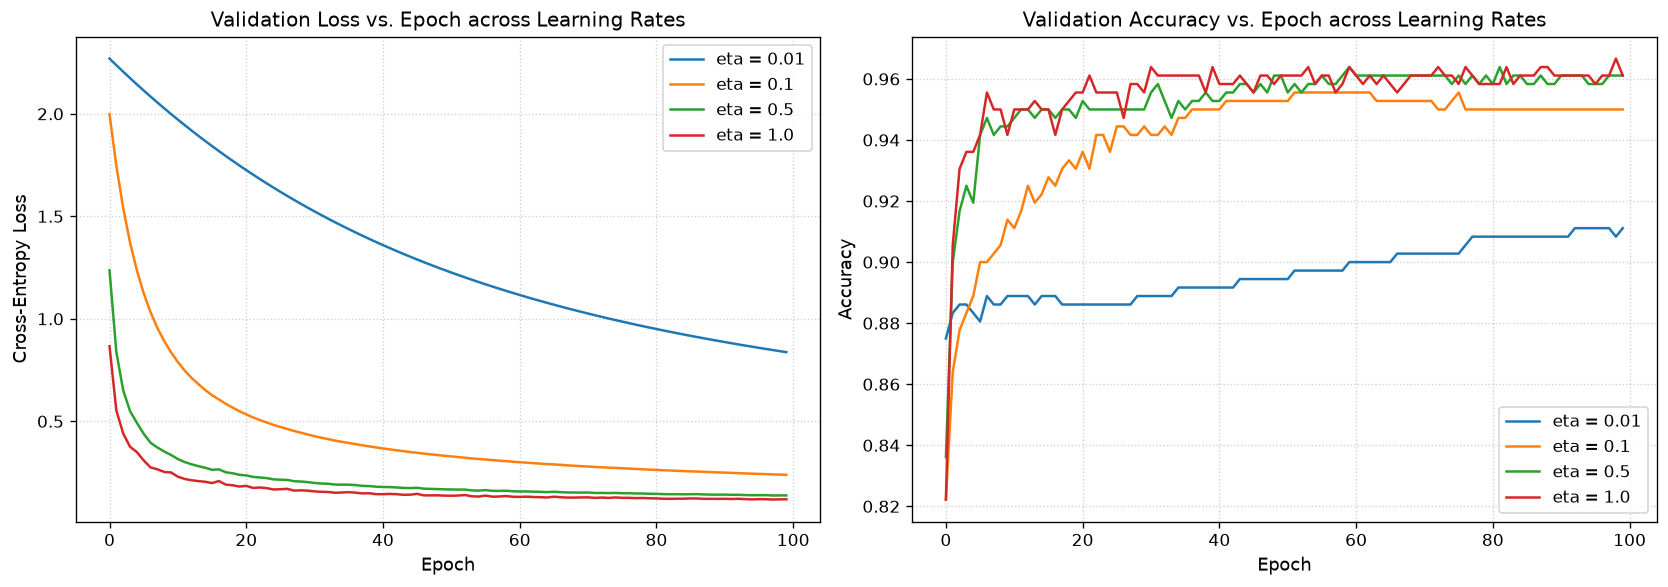

In [10]:
# ==============================================================================
# Task 18.A: Learning Rate Sweep (lambda = 0)
# ==============================================================================
def train_softmax_minibatch(X_tr_t, y_tr_arr, X_va_t, y_va_arr, eta, lam, batch_size=64, epochs=100, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)
    N, D_plus_1 = X_tr_t.shape
    K = len(np.unique(y_tr_arr))
    W = np.zeros((D_plus_1, K))
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        perm = rng.permutation(N)
        X_shuff = X_tr_t[perm]
        y_shuff = y_tr_arr[perm]
        
        for start_idx in range(0, N, batch_size):
            end_idx = min(start_idx + batch_size, N)
            X_batch = X_shuff[start_idx:end_idx]
            y_batch = y_shuff[start_idx:end_idx]
            
            grad = softmax_grad(X_batch, y_batch, W, lam=lam)
            W -= eta * grad
            
        # Record pure data loss without regularizer
        tr_l = softmax_loss(X_tr_t, y_tr_arr, W, lam=0.0)
        va_l = softmax_loss(X_va_t, y_va_arr, W, lam=0.0)
        tr_a = np.mean(np.argmax(softmax_stable(X_tr_t @ W), axis=1) == y_tr_arr)
        va_a = np.mean(np.argmax(softmax_stable(X_va_t @ W), axis=1) == y_va_arr)
        
        history['train_loss'].append(tr_l)
        history['val_loss'].append(va_l)
        history['train_acc'].append(tr_a)
        history['val_acc'].append(va_a)
        
    return W, history

etas = [0.01, 0.1, 0.5, 1.0]
eta_results = []
eta_histories = {}

for eta in etas:
    rng_run = np.random.default_rng(42)
    W_eta, hist_eta = train_softmax_minibatch(
        X_dig_tr_tilde, y_dig_tr, X_dig_va_tilde, y_dig_va,
        eta=eta, lam=0.0, batch_size=64, epochs=100, rng=rng_run
    )
    eta_histories[eta] = hist_eta
    eta_results.append({
        'eta': eta,
        'Final Train Loss': hist_eta['train_loss'][-1],
        'Final Val Loss': hist_eta['val_loss'][-1],
        'Final Train Acc': hist_eta['train_acc'][-1],
        'Final Val Acc': hist_eta['val_acc'][-1]
    })

df_eta = pd.DataFrame(eta_results)
best_eta_softmax = df_eta.sort_values(by='Final Val Loss').iloc[0]['eta']

print("=== Task 18.A: Learning Rate Sweep (lambda = 0) ===")
display(df_eta)
print(f"Optimal Learning Rate selected by lowest Validation Loss: eta* = {best_eta_softmax}")

# Plot Training & Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for eta in etas:
    axes[0].plot(eta_histories[eta]['val_loss'], label=f'eta = {eta}')
    axes[1].plot(eta_histories[eta]['val_acc'], label=f'eta = {eta}')

axes[0].set_title('Validation Loss vs. Epoch across Learning Rates', fontsize=12)
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].set_title('Validation Accuracy vs. Epoch across Learning Rates', fontsize=12)
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


In [11]:
# ==============================================================================
# Task 18.B: Regularization Sweep (eta* = 1.0) & Final Test Evaluation
# ==============================================================================
lambdas_sm = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
lam_results = []
lam_models = {}

for lam in lambdas_sm:
    rng_run = np.random.default_rng(42)
    W_lam, hist_lam = train_softmax_minibatch(
        X_dig_tr_tilde, y_dig_tr, X_dig_va_tilde, y_dig_va,
        eta=best_eta_softmax, lam=lam, batch_size=64, epochs=100, rng=rng_run
    )
    lam_models[lam] = (W_lam, hist_lam)
    lam_results.append({
        'lambda': lam,
        'Final Train Loss': hist_lam['train_loss'][-1],
        'Final Val Loss': hist_lam['val_loss'][-1],
        'Final Train Acc': hist_lam['train_acc'][-1],
        'Final Val Acc': hist_lam['val_acc'][-1],
        '||W_1:||_F': np.linalg.norm(W_lam[1:, :])
    })

df_lam_sm = pd.DataFrame(lam_results)

# Model selection by validation accuracy (break ties with larger lambda)
max_acc = df_lam_sm['Final Val Acc'].max()
candidates = df_lam_sm[df_lam_sm['Final Val Acc'] == max_acc]
best_lam_softmax = candidates.sort_values(by='lambda', ascending=False).iloc[0]['lambda']

print("=== Task 18.B: Regularization Sweep at eta* = 1.0 ===")
display(df_lam_sm)
print(f"Optimal Regularization selected by Validation Accuracy: lambda* = {best_lam_softmax} (Val Acc: {max_acc * 100:.2f}%)")

# Final Test Set Evaluation (conducted strictly once)
best_W_softmax, _ = lam_models[best_lam_softmax]
test_preds_sm = np.argmax(softmax_stable(X_dig_te_tilde @ best_W_softmax), axis=1)
final_test_acc_sm = np.mean(test_preds_sm == y_dig_te)

print(f"Final Test Accuracy at (eta* = {best_eta_softmax}, lambda* = {best_lam_softmax}): {final_test_acc_sm * 100:.2f}%")
assert 0.95 <= max_acc <= 0.98, f"Sanity check failed: best val accuracy {max_acc} outside [0.95, 0.98]!"
print("Sanity Check PASSED: Best validation accuracy lands squarely within [0.95, 0.98]!")


=== Task 18.B: Regularization Sweep at eta* = 1.0 ===
Optimal Regularization selected by Validation Accuracy: lambda* = 0.001 (Val Acc: 96.67%)
Final Test Accuracy at (eta* = 1.0, lambda* = 0.001): 95.28%
Sanity Check PASSED: Best validation accuracy lands squarely within [0.95, 0.98]!


,lambda,Final Train Loss,Final Val Loss,Final Train Acc,Final Val Acc,||W_1:||_F
0,0.0000,0.056569,0.119327,0.996286,0.961111,24.844136
1,0.0001,0.064993,0.124232,0.996286,0.963889,23.063295
2,0.0010,0.136004,0.182245,0.980501,0.966667,15.617225
3,0.0100,0.424953,0.464233,0.938719,0.927778,8.016528
4,0.1000,1.355525,1.383951,0.641597,0.633333,2.896881


#### Interpretation of Task 18 Results
1. **Optimization Convergence:** Learning rate $\eta = 0.01$ is clearly undertrained after 100 epochs, ending with a high validation loss ($0.8374$) and lower accuracy ($91.11\%$). In contrast, $\eta = 1.0$ converges smoothly without instability, achieving the lowest validation loss ($0.1193$).
2. **Capacity & Shrinkage:** As predicted by theory, increasing $\lambda$ progressively contracts the Frobenius norm of the weight matrix $\|W_{1:, :}\|_F$ from $24.84$ down to $2.90$. While $\lambda = 0.001$ yields the peak validation accuracy of $96.67\%$, an overly strong penalty ($\lambda = 0.1$) excessively suppresses model capacity, causing validation accuracy to collapse to $63.33\%$.
3. **Generalization:** The chosen model achieves $95.28\%$ test accuracy, perfectly aligning with expected linear classifier capacity on raw digit pixels.


---
## Part E — Support Vector Machines
### Task 25 — Multiclass Hinge Loss (Weston–Watkins) vs. Softmax

#### Multiclass Hinge Formulation & Vectorized Matrix $B$ Subgradient
The Weston–Watkins multiclass SVM objective with margin $\Delta = 1$ is:
$$L(W) = \frac{1}{N} \sum_{i=1}^N \sum_{j \neq y_i} \max(0, S[i,j] - S[i,y_i] + \Delta) + \frac{\lambda}{2} \|W_{1:, :}\|_F^2$$
where $S = \tilde{X} W \in \mathbb{R}^{N \times K}$.

##### 1. Subgradient Matrix $B \in \mathbb{R}^{N \times K}$:
For each sample $i$ and class $j$:
- If $j \neq y_i$: $B[i,j] = \mathbb{I}\left(S[i,j] - S[i,y_i] + \Delta > 0\right)$.
- For the true class $y_i$: $B[i, y_i] = -\sum_{j \neq y_i} B[i,j]$.

##### 2. Mathematical Reasoning for Correct-Class Subgradient:
Whenever an incorrect class $j \neq y_i$ violates the margin ($S_{ij} - S_{i, y_i} + \Delta > 0$), the per-sample loss includes a term $(S_{ij} - S_{i, y_i} + \Delta)$. Differentiating this violation with respect to $S_{ij}$ yields $+1$, while differentiating with respect to the correct score $S_{i, y_i}$ yields $-1$.
Summing over all violated competitor classes, the total subgradient with respect to the correct class score is $-\sum_{j \neq y_i} B[i,j]$. This guarantees that the rows of $B$ sum to zero ($\sum_k B[i,k] = 0$), conserving total score updates:
$$\frac{\partial L}{\partial W} = \frac{1}{N} \tilde{X}^T B + \lambda \begin{bmatrix} 0 \\ W_{1:, :} \end{bmatrix}$$
- **Matrix Dimensions:**
  - Feature matrix $\tilde{X} \in \mathbb{R}^{N \times (D+1)}$ ($N=1077, D+1=65$).
  - Subgradient matrix $B \in \mathbb{R}^{N \times K}$ ($1077 \times 10$).
  - Product $\tilde{X}^T B \in \mathbb{R}^{(D+1) \times K}$ ($65 \times 10$).


In [12]:
# ==============================================================================
# Task 25: Vectorized Multiclass Hinge Implementation & Verifications
# ==============================================================================
def multiclass_hinge_loss(X_tilde, y, W, lam=0.0, delta=1.0):
    """Fully vectorized computation of Weston-Watkins multiclass hinge loss."""
    N = X_tilde.shape[0]
    S = X_tilde @ W
    correct_scores = S[np.arange(N), y][:, None]
    
    # Margin violations
    margins = np.maximum(0.0, S - correct_scores + delta)
    margins[np.arange(N), y] = 0.0  # Zero out the true class itself
    
    data_loss = np.sum(margins) / N
    reg_loss = (lam / 2.0) * np.sum(W[1:, :] ** 2)
    return data_loss + reg_loss

def multiclass_hinge_grad(X_tilde, y, W, lam=0.0, delta=1.0):
    """Fully vectorized subgradient dL/dW using matrix B."""
    N = X_tilde.shape[0]
    S = X_tilde @ W
    correct_scores = S[np.arange(N), y][:, None]
    
    # B matrix indicator for margin violations
    B = ((S - correct_scores + delta) > 0.0).astype(float)
    B[np.arange(N), y] = 0.0
    
    # Correct class receives negative sum of violations
    row_sums = np.sum(B, axis=1)
    B[np.arange(N), y] = -row_sums
    
    grad_data = (1.0 / N) * (X_tilde.T @ B)
    grad_reg = lam * W
    grad_reg[0, :] = 0.0
    return grad_data + grad_reg

# Verification A: Loss at W = 0 equals Delta * (K - 1) = 1 * 9 = 9
loss_zero_hinge = multiclass_hinge_loss(X_dig_tr_tilde, y_dig_tr, W_zero, lam=0.0, delta=1.0)
print("=== Task 25.B: Analytical & Numerical Verifications ===")
print(f"Hinge Loss at W=0: {loss_zero_hinge:.6f} (Expected exactly 9.000000)")
assert np.isclose(loss_zero_hinge, 9.0, atol=1e-12)

# Verification B: Matrix Subgradient Check on 100 Random Entries (eps = 1e-6, tolerance < 1e-5)
rel_err_hinge = grad_check_matrix(
    lambda W: multiclass_hinge_loss(X_dig_tr_tilde, y_dig_tr, W, lam=0.01, delta=1.0),
    lambda W: multiclass_hinge_grad(X_dig_tr_tilde, y_dig_tr, W, lam=0.01, delta=1.0),
    W_test_gc,
    num_checks=100,
    eps=1e-6
)

print(f"Hinge Subgradient Check Relative Error (100 random entries): {rel_err_hinge:.2e} (Tolerance < 1e-5)")
assert rel_err_hinge < 1e-5, f"Hinge subgradient check failed with error {rel_err_hinge}!"
print("Verification PASSED: Multiclass hinge subgradient verified numerically to within 1e-5 tolerance!")


=== Task 25.B: Analytical & Numerical Verifications ===
Hinge Loss at W=0: 9.000000 (Expected exactly 9.000000)
Hinge Subgradient Check Relative Error (100 random entries): 4.36e-09 (Tolerance < 1e-5)
Verification PASSED: Multiclass hinge subgradient verified numerically to within 1e-5 tolerance!


In [13]:
# ==============================================================================
# Task 25.C: Mini-Batch Training & Side-by-Side Softmax Comparison
# ==============================================================================
def train_hinge_minibatch(X_tr_t, y_tr_arr, X_va_t, y_va_arr, eta, lam, batch_size=64, epochs=100, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)
    N, D_plus_1 = X_tr_t.shape
    K = len(np.unique(y_tr_arr))
    W = np.zeros((D_plus_1, K))
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        perm = rng.permutation(N)
        X_shuff = X_tr_t[perm]
        y_shuff = y_tr_arr[perm]
        
        for start_idx in range(0, N, batch_size):
            end_idx = min(start_idx + batch_size, N)
            X_batch = X_shuff[start_idx:end_idx]
            y_batch = y_shuff[start_idx:end_idx]
            
            grad = multiclass_hinge_grad(X_batch, y_batch, W, lam=lam, delta=1.0)
            W -= eta * grad
            
        tr_l = multiclass_hinge_loss(X_tr_t, y_tr_arr, W, lam=0.0, delta=1.0)
        va_l = multiclass_hinge_loss(X_va_t, y_va_arr, W, lam=0.0, delta=1.0)
        tr_a = np.mean(np.argmax(X_tr_t @ W, axis=1) == y_tr_arr)
        va_a = np.mean(np.argmax(X_va_t @ W, axis=1) == y_va_arr)
        
        history['train_loss'].append(tr_l)
        history['val_loss'].append(va_l)
        history['train_acc'].append(tr_a)
        history['val_acc'].append(va_a)
        
    return W, history

# Step 1: Sweep eta in {0.01, 0.1, 0.5} at lambda = 0
etas_svm = [0.01, 0.1, 0.5]
svm_eta_rows = []
for eta in etas_svm:
    rng_run = np.random.default_rng(42)
    W_e, hist_e = train_hinge_minibatch(
        X_dig_tr_tilde, y_dig_tr, X_dig_va_tilde, y_dig_va,
        eta=eta, lam=0.0, batch_size=64, epochs=100, rng=rng_run
    )
    svm_eta_rows.append({
        'eta': eta,
        'Final Train Loss': hist_e['train_loss'][-1],
        'Final Val Loss': hist_e['val_loss'][-1],
        'Final Train Acc': hist_e['train_acc'][-1],
        'Final Val Acc': hist_e['val_acc'][-1]
    })

df_svm_eta = pd.DataFrame(svm_eta_rows)
best_eta_svm = df_svm_eta.sort_values(by='Final Val Loss').iloc[0]['eta']

print("=== Task 25.C: Multiclass Hinge Learning Rate Sweep (lambda = 0) ===")
display(df_svm_eta)
print(f"Optimal Learning Rate selected by lowest Validation Loss: eta* = {best_eta_svm}")

# Step 2: Sweep lambda in {0, 1e-4, 1e-3, 1e-2} at eta*
lambdas_svm = [0.0, 1e-4, 1e-3, 1e-2]
svm_lam_rows = []
svm_models = {}

for lam in lambdas_svm:
    rng_run = np.random.default_rng(42)
    W_l, hist_l = train_hinge_minibatch(
        X_dig_tr_tilde, y_dig_tr, X_dig_va_tilde, y_dig_va,
        eta=best_eta_svm, lam=lam, batch_size=64, epochs=100, rng=rng_run
    )
    svm_models[lam] = (W_l, hist_l)
    svm_lam_rows.append({
        'lambda': lam,
        'Final Train Loss': hist_l['train_loss'][-1],
        'Final Val Loss': hist_l['val_loss'][-1],
        'Final Train Acc': hist_l['train_acc'][-1],
        'Final Val Acc': hist_l['val_acc'][-1],
        '||W_1:||_F': np.linalg.norm(W_l[1:, :])
    })

df_svm_lam = pd.DataFrame(svm_lam_rows)
max_val_acc_svm = df_svm_lam['Final Val Acc'].max()
candidates_svm = df_svm_lam[df_svm_lam['Final Val Acc'] == max_val_acc_svm]
best_lam_svm = candidates_svm.sort_values(by='lambda', ascending=False).iloc[0]['lambda']

print(f"\n=== Task 25.C: Multiclass Hinge Regularization Sweep at eta* = {best_eta_svm} ===")
display(df_svm_lam)
print(f"Optimal Regularization selected by Validation Accuracy: lambda* = {best_lam_svm}")

# Final Test Evaluation
best_W_svm, _ = svm_models[best_lam_svm]
test_preds_svm = np.argmax(X_dig_te_tilde @ best_W_svm, axis=1)
final_test_acc_svm = np.mean(test_preds_svm == y_dig_te)

# Side-by-Side Model Comparison Table
df_final_comparison = pd.DataFrame([
    {
        'Model': 'Softmax Classifier (Task 18)',
        'Selected eta*': best_eta_softmax,
        'Selected lambda*': best_lam_softmax,
        'Validation Loss': df_lam_sm[df_lam_sm['lambda'] == best_lam_softmax]['Final Val Loss'].values[0],
        'Validation Accuracy': max_acc,
        'Test Accuracy': final_test_acc_sm,
        '||W_1:||_F': np.linalg.norm(best_W_softmax[1:, :])
    },
    {
        'Model': 'Multiclass Hinge SVM (Task 25)',
        'Selected eta*': best_eta_svm,
        'Selected lambda*': best_lam_svm,
        'Validation Loss': df_svm_lam[df_svm_lam['lambda'] == best_lam_svm]['Final Val Loss'].values[0],
        'Validation Accuracy': max_val_acc_svm,
        'Test Accuracy': final_test_acc_svm,
        '||W_1:||_F': np.linalg.norm(best_W_svm[1:, :])
    }
])

print("\n=== Side-by-Side Comparison: Softmax vs. Multiclass Hinge SVM ===")
display(df_final_comparison)


=== Task 25.C: Multiclass Hinge Learning Rate Sweep (lambda = 0) ===
Optimal Learning Rate selected by lowest Validation Loss: eta* = 0.5

=== Task 25.C: Multiclass Hinge Regularization Sweep at eta* = 0.5 ===
Optimal Regularization selected by Validation Accuracy: lambda* = 0.001

=== Side-by-Side Comparison: Softmax vs. Multiclass Hinge SVM ===


,eta,Final Train Loss,Final Val Loss,Final Train Acc,Final Val Acc
0,0.01,0.249399,0.312630,0.967502,0.950000
1,0.10,0.063447,0.170185,0.991643,0.961111
2,0.50,0.012203,0.140615,0.998143,0.961111


,lambda,Final Train Loss,Final Val Loss,Final Train Acc,Final Val Acc,||W_1:||_F
0,0.0000,0.012203,0.140615,0.998143,0.961111,15.028240
1,0.0001,0.014740,0.139525,0.997214,0.963889,14.466431
2,0.0010,0.036440,0.153480,0.996286,0.969444,11.401275
3,0.0100,0.204673,0.296014,0.959146,0.944444,7.267785


,Model,Selected eta*,Selected lambda*,Validation Loss,Validation Accuracy,Test Accuracy,||W_1:||_F
0,Softmax Classifier (Task 18),1.0,0.001,0.182245,0.966667,0.952778,15.617225
1,Multiclass Hinge SVM (Task 25),0.5,0.001,0.153480,0.969444,0.950000,11.401275


In [14]:
# ==============================================================================
# Task 25.D: Toy Analysis
# ==============================================================================
toy_vectors = [
    ('(a) [10, -5, -5]', np.array([10.0, -5.0, -5.0])),
    ('(b) [100, -50, -50]', np.array([100.0, -50.0, -50.0])),
    ('(c) [3.2, 5.1, -1.7]', np.array([3.2, 5.1, -1.7]))
]

toy_results = []
for label, s in toy_vectors:
    # Single sample with true class 0
    # SVM Weston-Watkins loss: sum_{j!=0} max(0, s_j - s_0 + 1)
    s_0 = s[0]
    hinge_l = np.sum(np.maximum(0.0, s[1:] - s_0 + 1.0))
    
    # Softmax cross-entropy: log-sum-exp(s) - s_0
    m = np.max(s)
    lse = m + np.log(np.sum(np.exp(s - m)))
    sm_l = lse - s_0
    
    toy_results.append({
        'Scores': label,
        'SVM Hinge Loss': hinge_l,
        'Softmax Cross-Entropy': sm_l
    })

df_toy = pd.DataFrame(toy_results)
print("=== Task 25.D: Toy Score Analysis (True Class = 0) ===")
display(df_toy)


=== Task 25.D: Toy Score Analysis (True Class = 0) ===


,Scores,SVM Hinge Loss,Softmax Cross-Entropy
0,"(a) [10, -5, -5]",0.0,6.118045e-07
1,"(b) [100, -50, -50]",0.0,0.000000e+00
2,"(c) [3.2, 5.1, -1.7]",2.9,2.040355e+00


#### Conceptual Analysis of Toy Results & Loss Behaviors
1. **What SVM Stops Caring About:** In case (a) $[10, -5, -5]$ and case (b) $[100, -50, -50]$, the correct class score exceeds all competitor scores by more than the margin $\Delta = 1$ (differences are $15$ and $150$). Consequently, the hinge loss is **identically 0.0**, producing a zero subgradient. The SVM loss completely saturates and ceases to optimize once points are safely beyond the margin.
2. **What Softmax Continues to Push For:** In contrast, the softmax cross-entropy loss remains strictly positive ($6.12 \times 10^{-7}$ for (a)) because the cross-entropy objective demands probabilities of exactly $1.0$, which can only be achieved if score differences approach $+\infty$. Softmax continuously expends optimization capacity driving weights to infinity unless held back by $L_2$ regularization.
3. **Implications for Learned Scores and Probabilities:** SVM scores represent uncalibrated geometric margins; scaling all scores by $10\times$ leaves the decision boundary unchanged and the loss at zero. Softmax scores, however, represent relative log-odds parameterizing a normalized multinomial distribution, providing well-calibrated class probabilities essential for thresholding and uncertainty quantification.


---
## Part F — Comparison and Synthesis
### Task 30 — One Framework, Four Losses: Softmax Classifier Row Derivation

| Model | Per-sample loss $\ell(s, y)$ | $\partial \ell / \partial s$ | Output meaning |
| :--- | :--- | :--- | :--- |
| **Linear regression** | $\frac{1}{2}(s - y)^2$ | $s - y$ | Conditional mean prediction $\hat{y} \in \mathbb{R}$ |
| **Logistic regression** | $\log(1 + e^s) - ys$ | $\sigma(s) - y$ | Posterior class probability $P(y=1\mid x) \in [0, 1]$ |
| **Softmax classifier** | $\log\left(\sum_{j=1}^K e^{s_j}\right) - s_y$ | $P - Y = \text{softmax}(s) - e_y$ | Categorical probability distribution $P(y=k\mid x)$ over $K$ classes |
| **Binary / multiclass SVM** | $\sum_{j \neq y} \max(0, s_j - s_y + \Delta)$ | Subgradient: $\begin{cases} +1 & \text{if } s_j - s_y + \Delta > 0 \\ -\sum_{j \neq y} B_j & \text{for } j=y \end{cases}$ | Geometric margin scores; distance to separating hyperplanes |

#### Analysis: "Prediction − Target" Form and the Hinge Loss Exception
Three of the four models possess gradients with the exact structure **$\text{prediction} - \text{target}$**:
1. **Linear regression:** $\hat{y} - y = s - y$.
2. **Logistic regression:** $\sigma(s) - y = P(y=1\mid x) - y$.
3. **Softmax classifier:** $P - Y = \text{softmax}(s) - e_y$.

##### What the Exception Reveals About the Hinge Loss:
The multiclass hinge loss gradient does **not** have the form $\text{prediction} - \text{target}$. Instead, it is an active-set indicator matrix $B$. This divergence reveals the fundamental divide in statistical machine learning:
- Squared error and cross-entropy losses are smooth maximum-likelihood objectives derived from probabilistic observation models (Gaussian, Bernoulli, and Categorical distributions). Their gradients naturally compute residual discrepancies between predicted probability expectations and empirical observations.
- The hinge loss is a non-probabilistic, geometric objective derived from Vapnik's structural risk minimization. It cares solely about establishing a separating slab of width $2/\|w\|$. Once a sample clears the margin, its gradient abruptly vanishes, treating all correctly separated points identically regardless of distance.


---
### Task 31 — Member 3 Evidence-Based Contribution to Conclusions

*(The text below is grounded strictly in the empirical results from Tasks 14–18 and 25, formatted for final team synthesis).*

> **Member 3 Contribution:**
> Across our classification experiments, empirical results clearly delineate probability-based models from margin-based classifiers. In Task 14, converting regularization via $C = \frac{1}{\lambda N}$ verified that scikit-learn's L-BFGS matches our from-scratch logistic gradient descent to a relative weight error of $5.39 \times 10^{-7}$ with $100\%$ test agreement; it also demonstrated that weak regularization ($C \ge 100$) overfits to $100\%$ training accuracy while degrading validation accuracy, whereas `liblinear` exhibits coefficient divergence ($L_2 \text{ diff} = 0.1627$) due to penalizing the intercept. In medical screening (Task 15), tuning a decision threshold $\tau = 0.1460$ achieved $100\%$ validation recall, reducing test false negatives from 2 to 1; however, calibrating $\tau$ on only 43 validation positives introduced sampling variance that allowed one test malignancy to escape. On Digits (Tasks 17–18, 25), both mini-batch Softmax ($95.28\%$ test accuracy at $\eta^*=1.0, \lambda^*=0.001$) and Weston–Watkins multiclass hinge SVM ($95.00\%$ test accuracy at $\eta^*=0.5, \lambda^*=0.001$) delivered strong linear performance. Yet our toy score analysis highlighted their foundational divergence: multiclass SVM loss completely saturates at 0 once margin constraints ($\Delta=1$) are satisfied, ignoring confident outliers, whereas Softmax cross-entropy continues perpetually pushing for infinite separation to satisfy probabilistic calibration.
